# ENSO e soja: análise exploratória

Pergunta: o ciclo El Niño / La Niña (ENSO) mexe no clima das regiões produtoras de soja e, por esse caminho, no rendimento? Se sim, onde, com quanto atraso e por qual variável do clima?

Dados: índices ONI e RONI (NOAA CPC), temperatura do mar ERSST v5, estações do INMET (chuva e temperatura máxima), PAM/IBGE (rendimento da soja por município) e a grade de temperatura máxima CPC Global Unified (NOAA).

In [1]:
import subprocess
import warnings
from pathlib import Path

import geobr
import geopandas as gpd
import matplotlib.patches as mpatches
import matplotlib.pyplot as plt
import netCDF4
import numpy as np
import pandas as pd
from scipy import stats
from scipy.stats import rankdata
from statsmodels.nonparametric.smoothers_lowess import lowess
from statsmodels.stats.multitest import multipletests

from soja_clima.geo import mapa_estacoes_cd_micro

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=RuntimeWarning)
pd.set_option("display.width", 200)

RAW = Path("../../data/raw")
PROCESSED = Path("../../data/processed")
MESES_SAFRA = [9, 10, 11, 12, 1, 2, 3, 4]          # safra = setembro a abril
FASES_CORES = {"El Niño": "#c0392b", "neutro": "#999999", "La Niña": "#2471a3"}
LARANJA, TEAL, INK, CINZA = "#A4561A", "#16707F", "#14261F", "#8A968F"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False})

## 1. O índice do ENSO: ONI e RONI

O ONI é a anomalia da temperatura do mar na região Niño 3.4 (5°N–5°S, 170°O–120°O), em média de 3 meses. Desde 2026 a NOAA usa o RONI, que mede a mesma região em relação ao resto dos trópicos. Antes de usar qualquer um, vale olhar os arquivos e entender a diferença.

In [2]:
ARQ = {
    "oni": (RAW / "oni_cpc_noaa.txt", "https://www.cpc.ncep.noaa.gov/data/indices/oni.ascii.txt"),
    "roni": (RAW / "roni_cpc_noaa.txt", "https://www.cpc.ncep.noaa.gov/data/indices/RONI.ascii.txt"),
    "ersst": (RAW / "ersst_v5_sst_mnmean.nc", "https://downloads.psl.noaa.gov/Datasets/noaa.ersst.v5/sst.mnmean.nc"),
}
for caminho, url in ARQ.values():
    if not caminho.exists():
        subprocess.run(["curl", "-sS", "-f", "--retry", "3", "-o", str(caminho), url], check=True)

for nome in ("oni", "roni"):
    print("\n".join(ARQ[nome][0].read_text().splitlines()[:6]), "\n")

 SEAS  YR   TOTAL   ANOM
  DJF 1950  25.01  -1.32
  JFM 1950  25.36  -1.20
  FMA 1950  25.88  -1.12
  MAM 1950  26.24  -1.08
  AMJ 1950  26.35  -1.10 

SEAS   YR  ANOM
DJF  1950 -1.19
JFM  1950 -1.08
FMA  1950 -0.96
MAM  1950 -1.00
AMJ  1950 -0.99 



In [3]:
ESTACOES = ["DJF", "JFM", "FMA", "MAM", "AMJ", "MJJ", "JJA", "JAS", "ASO", "SON", "OND", "NDJ"]


def ler_indice(caminho):
    d = pd.read_csv(caminho, sep=r"\s+")
    d.index = pd.to_datetime(dict(year=d["YR"], month=d["SEAS"].map({s: i + 1 for i, s in enumerate(ESTACOES)}), day=1))
    return d                                        # DJF vira janeiro (mês do meio)


oni_raw, roni_raw = ler_indice(ARQ["oni"][0]), ler_indice(ARQ["roni"][0])
ONI_M, RONI_M = oni_raw["ANOM"], roni_raw["ANOM"]

# o normal de 30 anos não vem numa coluna, mas sai de TOTAL − ANOM
oni_raw["NORMAL"] = (oni_raw["TOTAL"] - oni_raw["ANOM"]).round(2)
print(oni_raw.query("SEAS == 'OND' and YR in [1955, 1975, 1995, 2015, 2025]")[["YR", "TOTAL", "ANOM", "NORMAL"]].to_string(index=False))
print(f"\nmaior ONI desde 1980: {ONI_M['1980':].max():+.2f} °C ({ONI_M['1980':].idxmax():%m/%Y})")

  YR  TOTAL  ANOM  NORMAL
1955  24.63 -1.59   26.22
1975  24.98 -1.47   26.45
1995  25.66 -1.05   26.71
2015  29.10  2.45   26.65
2025  26.04 -0.61   26.65

maior ONI desde 1980: +2.59 °C (12/2015)


O normal de outubro–dezembro subiu de 26,22 °C (1955) para 26,65 °C (2015 e 2025): a NOAA troca o período de 30 anos a cada 5 anos, e ele acompanha o aquecimento do mar. O maior ONI desde 1980 foi +2,6 °C, no El Niño de 2015/16.

### Onde o ONI é medido
Para ver a região, o mapa do pico de 2015/16 com a ERSST v5 (anomalia em relação a 1991–2020).

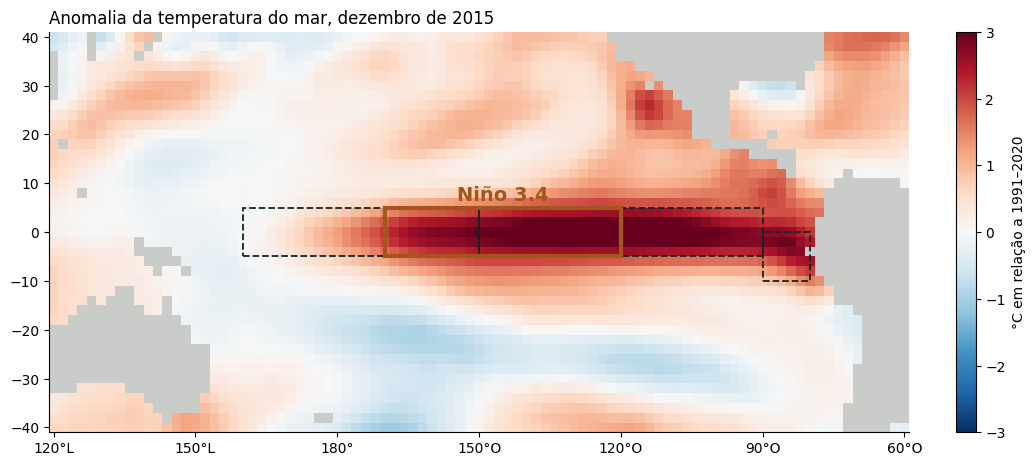

In [4]:
with netCDF4.Dataset(ARQ["ersst"][0]) as ds:
    lat, lon = ds["lat"][:], ds["lon"][:]
    datas_sst = netCDF4.num2date(ds["time"][:], ds["time"].units)
    sst = np.ma.filled(ds["sst"][:].astype(float), np.nan)
ano = np.array([d.year for d in datas_sst])
mes = np.array([d.month for d in datas_sst])
base = (ano >= 1991) & (ano <= 2020)
sst_anom = sst - np.stack([np.nanmean(sst[base & (mes == m)], axis=0) for m in range(1, 13)])[mes - 1]

i = np.where((ano == 2015) & (mes == 12))[0][0]
lo, la = (lon >= 120) & (lon <= 300), (lat >= -40) & (lat <= 40)
fig, ax = plt.subplots(figsize=(12, 5.2))
ax.set_facecolor("#C9CCC8")
m = ax.pcolormesh(lon[lo], lat[la], sst_anom[i][np.ix_(la, lo)], cmap="RdBu_r", vmin=-3, vmax=3, shading="nearest")
for nome, x0, x1, y0, y1 in [("Niño 4", 160, 210, -5, 5), ("Niño 3", 210, 270, -5, 5),
                             ("Niño 1+2", 270, 280, -10, 0), ("Niño 3.4", 190, 240, -5, 5)]:
    d34 = nome == "Niño 3.4"
    ax.add_patch(mpatches.Rectangle((x0, y0), x1 - x0, y1 - y0, fill=False, lw=3 if d34 else 1.3,
                                    ec=LARANJA if d34 else INK, ls="-" if d34 else "--"))
ax.text(215, 6.5, "Niño 3.4", color=LARANJA, fontsize=14, fontweight="bold", ha="center")
ax.set_xticks([120, 150, 180, 210, 240, 270, 300], ["120°L", "150°L", "180°", "150°O", "120°O", "90°O", "60°O"])
ax.set_title("Anomalia da temperatura do mar, dezembro de 2015", loc="left")
fig.colorbar(m, ax=ax, fraction=0.025, label="°C em relação a 1991–2020")
plt.show()

### Por que existe o RONI
Se o oceano tropical inteiro esquentou, parte do que o ONI chama de El Niño pode ser só esse aquecimento geral.

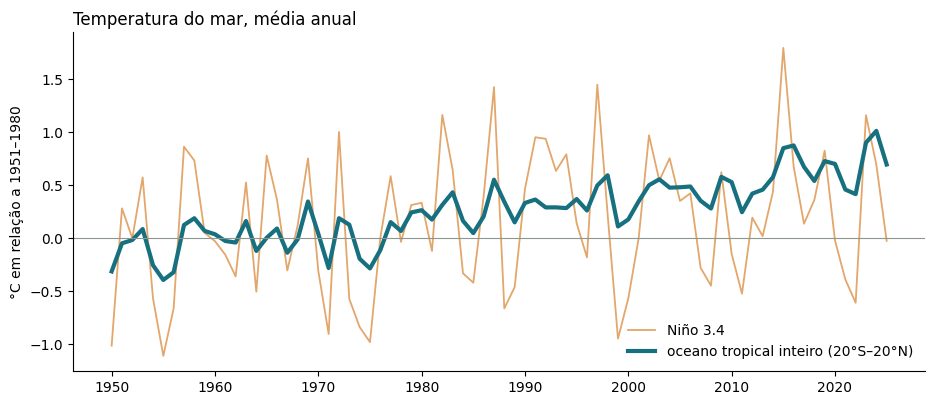

trópicos em 2016–2025: +0.70 °C em relação a 1951–1980


In [5]:
peso = np.cos(np.deg2rad(lat))
idx_mes = pd.to_datetime([f"{a}-{m:02d}-01" for a, m in zip(ano, mes)])


def media_area(mlat, mlon):
    sub = sst_anom[:, mlat][:, :, mlon]
    w = np.broadcast_to(peso[mlat][:, None], sub.shape[1:])
    return pd.Series(np.nansum(np.nan_to_num(sub) * w, axis=(1, 2)) / np.sum(np.isfinite(sub) * w, axis=(1, 2)), index=idx_mes)


TROP = media_area((lat >= -20) & (lat <= 20), np.ones_like(lon, bool))
N34 = media_area((lat >= -5) & (lat <= 5), (lon >= 190) & (lon <= 240))
anual = pd.DataFrame({"trópicos": TROP, "Niño 3.4": N34})["1950":"2025"].groupby(lambda d: d.year).mean()
anual -= anual.loc[1951:1980].mean()

fig, ax = plt.subplots(figsize=(11, 4.4))
ax.plot(anual.index, anual["Niño 3.4"], color="#E3A66B", lw=1.3, label="Niño 3.4")
ax.plot(anual.index, anual["trópicos"], color=TEAL, lw=3, label="oceano tropical inteiro (20°S–20°N)")
ax.axhline(0, color=CINZA, lw=0.8)
ax.set_ylabel("°C em relação a 1951–1980")
ax.legend(frameon=False, loc="lower right")
ax.set_title("Temperatura do mar, média anual", loc="left")
plt.show()
print(f"trópicos em 2016–2025: {anual.loc[2016:2025, 'trópicos'].mean():+.2f} °C em relação a 1951–1980")

Os trópicos subiram cerca de 0,7 °C. Refazendo o RONI pela definição da NOAA (Niño 3.4 menos a média dos trópicos, reescalado para a variância do Niño 3.4), com a ERSST v5 no lugar da v6:

In [6]:
n34_3m, trop_3m = N34.rolling(3, center=True).mean(), TROP.rolling(3, center=True).mean()
dif_3m = n34_3m - trop_3m
k = n34_3m["1950":"2025"].std() / dif_3m["1950":"2025"].std()
RONI_CALC = dif_3m * k

passos = pd.DataFrame({"Niño 3.4": n34_3m, "trópicos": trop_3m, "diferença": dif_3m,
                       f"× {k:.2f}": RONI_CALC, "RONI oficial": RONI_M}).loc[["2019-12-01", "2024-12-01"]].T.round(2)
passos.columns = ["dez/2019", "dez/2024"]
print(passos)
c = pd.concat([RONI_CALC, RONI_M], axis=1).dropna()
print(f"\nconta × oficial: r = {c.corr().iloc[0, 1]:.2f}, erro típico = {np.sqrt(((c.iloc[:, 0] - c.iloc[:, 1]) ** 2).mean()):.2f} °C")

              dez/2019  dez/2024
Niño 3.4          0.56     -0.52
trópicos          0.38      0.34
diferença         0.18     -0.86
× 1.23            0.22     -1.06
RONI oficial      0.22     -1.05

conta × oficial: r = 0.99, erro típico = 0.11 °C


A conta reproduz o oficial (r = 0,99, erro de 0,1 °C). Dez/2019: Pacífico quente, mas os trópicos também; o RONI fica neutro. Dez/2024: Pacífico mais frio que os trópicos; o RONI marca La Niña, que o ONI não via.

### ONI × RONI nas safras
Regra de fase usada no projeto: a safra (set–abr) é de El Niño (ou La Niña) se pelo menos 4 dos 8 meses estão nessa fase, contando só trechos de 5 ou mais meses além de ±0,5 °C.

In [7]:
def fase_mensal(s, limiar=0.5, n_min=5):
    out = pd.Series("neutro", index=s.index)
    for nome, cond in (("El Niño", s >= limiar), ("La Niña", s <= -limiar)):
        grupo = (cond != cond.shift()).cumsum()
        out[cond & (cond.groupby(grupo).transform("size") >= n_min)] = nome
    return out


def fase_safra(s):
    f = fase_mensal(s)
    f = f[f.index.month.isin(MESES_SAFRA)]
    return f.groupby(np.where(f.index.month >= 9, f.index.year + 1, f.index.year)).apply(
        lambda x: "El Niño" if (x == "El Niño").sum() >= 4 else ("La Niña" if (x == "La Niña").sum() >= 4 else "neutro"))


d = pd.concat([ONI_M, RONI_M], axis=1, keys=["ONI", "RONI"]).dropna()["1980":]
print(f"correlação ONI × RONI desde 1980: {d['ONI'].corr(d['RONI']):.2f}")
print("ONI − RONI por década:", (d["ONI"] - d["RONI"]).groupby((d.index.year // 10) * 10).mean().round(2).to_dict())

fases_idx = pd.DataFrame({"ONI": fase_safra(ONI_M), "RONI": fase_safra(RONI_M)}).loc[1981:2025]
fases_idx.index = [f"{s_ - 1}/{str(s_)[2:]}" for s_ in fases_idx.index]
print("\nsafras que mudam de fase:")
print(fases_idx[fases_idx["ONI"] != fases_idx["RONI"]])
print("\n2006–2025:", {c_: fases_idx.loc["2005/06":"2024/25", c_].value_counts().to_dict() for c_ in fases_idx})

correlação ONI × RONI desde 1980: 0.96
ONI − RONI por década: {1980: -0.0, 1990: -0.11, 2000: 0.01, 2010: 0.22, 2020: 0.44}

safras que mudam de fase:
             ONI     RONI
1992/93   neutro  El Niño
2014/15  El Niño   neutro
2016/17   neutro  La Niña
2019/20  El Niño   neutro
2024/25   neutro  La Niña

2006–2025: {'ONI': {'La Niña': 9, 'El Niño': 7, 'neutro': 4}, 'RONI': {'La Niña': 11, 'El Niño': 5, 'neutro': 4}}


Os dois índices andam juntos (r = 0,96) até 2010; depois o ONI fica mais quente (+0,22 °C nos anos 2010, +0,44 °C nos 2020). Em 2006–2025 mudam de fase 2014/15, 2016/17, 2019/20 e 2024/25: de 7 El Niños, 9 La Niñas e 4 neutras (ONI) para 5, 11 e 4 (RONI). As análises abaixo usam o ONI, que é o índice da base do projeto (idêntico ao publicado pela NOAA).

## 2. Chuva por microrregião

Chuva mensal das estações do INMET dentro de cada microrregião (mês válido com ≥ 80% dos dias), anomalia padronizada por mês do calendário (climatologia com ≥ 10 anos), só meses da safra e só microrregiões com soja na base de modelagem.

In [8]:
clima = pd.read_parquet(PROCESSED / "clima_diario.parquet", columns=["codigo_estacao", "data", "prec_total", "temp_max"])
clima["mes_ref"] = pd.to_datetime(clima["data"]).dt.to_period("M")
mapa = mapa_estacoes_cd_micro(PROCESSED / "clima_diario.parquet").dropna(subset=["CD_MICRO"])
mapa = mapa[mapa["origem"] == "dentro_do_poligono"]

pac = pd.read_parquet(PROCESSED / "pacifico_indices.parquet")
pac["mes_ref"] = pd.to_datetime(dict(year=pac["ano"], month=pac["mes"], day=1)).dt.to_period("M")
enso = pac.set_index("mes_ref")[["oni", "soi"]].sort_index()
enso = enso.reindex(pd.period_range(enso.index.min(), enso.index.max(), freq="M"))

producao = pd.read_csv(PROCESSED / "base_final_modelagem.csv", dtype={"CD_MICRO": str}).groupby("CD_MICRO")["producao_ton"].mean()
micro = geobr.read_micro_region(year=2020, show_progress=False)
micro["CD_MICRO"] = micro["code_micro"].astype(int).astype(str)
micro_idx = micro.set_index("CD_MICRO")

microregions_2020_simplified.parquet: 100%|██████████| 7.91M/7.91M [00:00<00:00, 22.7MB/s]


590 estação(ões) com coordenadas divergentes entre arquivos -- usando a mediana das coordenadas.
2 estação(ões) excluída(s) por estarem a mais de 150km de qualquer microrregião.
151 de 558 microrregiões não têm nenhuma estação dentro delas.
5 microrregião(ões) sem substituta dentro de 150km -- ficarão sem clima.


In [9]:
mensal = (clima.groupby(["codigo_estacao", "mes_ref"]).agg(chuva=("prec_total", "sum"), dias=("prec_total", "count")).reset_index())
mensal = mensal[mensal["dias"] >= 0.8 * mensal["mes_ref"].dt.days_in_month]
chuva_micro = (mensal.merge(mapa[["codigo_estacao", "CD_MICRO"]], on="codigo_estacao")
                     .groupby(["CD_MICRO", "mes_ref"])["chuva"].mean().reset_index())
chuva_micro["mes"] = chuva_micro["mes_ref"].dt.month
chuva_micro["safra"] = np.where(chuva_micro["mes"] >= 9, chuva_micro["mes_ref"].dt.year + 1, chuva_micro["mes_ref"].dt.year)

g = chuva_micro.groupby(["CD_MICRO", "mes"])["chuva"]
chuva_micro["z"] = ((chuva_micro["chuva"] - g.transform("mean")) / g.transform("std")).where(g.transform("count") >= 10)
anom = chuva_micro[chuva_micro["mes"].isin(MESES_SAFRA)].pivot(index="mes_ref", columns="CD_MICRO", values="z").sort_index()
anom = anom[[c for c in anom.columns if c in producao.index]].dropna(axis=1, how="all")
ano_safra = pd.Series(np.where(anom.index.month >= 9, anom.index.year + 1, anom.index.year), index=anom.index)
print(f"{anom.shape[0]} meses de safra × {anom.shape[1]} microrregiões")

173 meses de safra × 228 microrregiões


## 3. Como dividir o país

Antes de procurar atrasos, é preciso agrupar as microrregiões: o El Niño traz mais chuva ao Sul e menos ao Norte, e na média do Brasil os dois efeitos se anulam. Correlação ONI × chuva em cada microrregião (Spearman, com p pelo n efetivo de Bretherton, porque as séries mensais são autocorrelacionadas):

In [10]:
def corr_neff(x, y, n_min=24):
    ok = x.notna() & y.notna()
    n = int(ok.sum())
    if n < n_min:
        return np.nan, np.nan, n
    r = stats.spearmanr(x[ok], y[ok]).statistic
    a, b = np.nan_to_num(x[ok].autocorr(1)), np.nan_to_num(y[ok].autocorr(1))
    n_eff = float(np.clip(n * (1 - a * b) / (1 + a * b), 3, n))
    t = r * np.sqrt((n_eff - 2) / max(1 - r ** 2, 1e-12))
    return r, 2 * stats.t.sf(abs(t), df=n_eff - 2), n_eff


def enso_janela(indice="oni", lag=0, janela=1):
    # média do índice nos `janela` meses que terminam `lag` meses antes do mês da chuva
    return enso[indice].rolling(janela, min_periods=janela).mean().shift(lag)


x0 = enso_janela().reindex(anom.index)
r_oni = pd.Series({c: corr_neff(x0, anom[c])[0] for c in anom.columns}).dropna()
print(f"ρ por microrregião: mediana {r_oni.median():+.2f}, de {r_oni.min():+.2f} a {r_oni.max():+.2f}")

ρ por microrregião: mediana +0.01, de -0.41 a +0.55


Divisões candidatas. Bioma e região intermediária são atribuídos pela maior área de interseção; o Pantanal tem só 2 microrregiões com soja, então testamos também juntá-lo ao Cerrado.

In [11]:
def por_maior_area(camada, coluna):
    m_ = micro[["CD_MICRO", "geometry"]].to_crs(5880)
    c_ = camada[[coluna, "geometry"]].to_crs(5880)
    m_["geometry"], c_["geometry"] = m_.geometry.make_valid(), c_.geometry.make_valid()
    inter = gpd.overlay(m_, c_, how="intersection", keep_geom_type=True)
    inter["area"] = inter.area
    return inter.sort_values("area").drop_duplicates("CD_MICRO", keep="last").set_index("CD_MICRO")[coluna]


biomas = geobr.read_biomes(year=2019, show_progress=False)
biomas = biomas[~biomas["name_biome"].str.contains("Costeiro", case=False, na=False)]
intermed = geobr.read_intermediate_region(year=2020, show_progress=False)
intermed["rotulo"] = intermed["name_intermediate"].astype(str) + " (" + intermed["abbrev_state"].astype(str) + ")"

uf, macro = micro_idx["abbrev_state"], micro_idx["name_region"]
bioma_ibge = por_maior_area(biomas, "name_biome")
matopiba = uf.isin(["MA", "TO", "PI", "BA"]) & (bioma_ibge.reindex(micro_idx.index) == "Cerrado")
n_uf = uf.reindex(anom.columns).value_counts()
divisoes = {
    "Macrorregião (5)": macro,
    "UF (27)": uf,
    "Bioma (IBGE)": bioma_ibge,
    "Região intermediária (IBGE)": por_maior_area(intermed, "rotulo"),
    "Macrorregião + MATOPIBA": macro.where(~matopiba, "MATOPIBA"),
    "UF (pequenas → macrorregião)": uf.where(~uf.isin(n_uf[n_uf < 3].index), "resto " + macro),
    "Bioma (Pantanal → Cerrado)": bioma_ibge.replace({"Pantanal": "Cerrado"}),
}
BIOMA = divisoes["Bioma (Pantanal → Cerrado)"]
print({k: v.reindex(anom.columns).nunique() for k, v in divisoes.items()})

{'Macrorregião (5)': 5, 'UF (27)': 23, 'Bioma (IBGE)': 6, 'Região intermediária (IBGE)': 94, 'Macrorregião + MATOPIBA': 6, 'UF (pequenas → macrorregião)': 21, 'Bioma (Pantanal → Cerrado)': 5}


Duas formas de medir se uma divisão agrupa bem:
- **dentro da amostra:** R² ajustado do ρ de cada microrregião explicado pela sua região;
- **fora da amostra:** o ρ das safras pares, pela média da região sem a própria microrregião, prevê o ρ das safras ímpares (e vice-versa).

In [12]:
def r2_ajustado(valores, grupos):
    d = pd.DataFrame({"v": valores, "g": grupos}).dropna()
    n, k_ = len(d), d["g"].nunique()
    ssw = ((d["v"] - d.groupby("g")["v"].transform("mean")) ** 2).sum()
    return 1 - (ssw / (n - k_)) / (((d["v"] - d["v"].mean()) ** 2).sum() / (n - 1))


def r_micro(mascara, lag=0):
    x = enso_janela("oni", lag).reindex(anom.index)[mascara]
    return pd.Series({c: corr_neff(x, anom[c][mascara], n_min=20)[0] for c in anom.columns}).dropna()


def r2_fora(rp, ri, rotulos):
    def prever(tr, te):
        comum = tr.index.intersection(te.index)
        lab = rotulos.reindex(comum).dropna()
        tr, te = tr[lab.index], te[lab.index]
        soma, n = tr.groupby(lab).transform("sum"), tr.groupby(lab).transform("count")
        pred = ((soma - tr) / (n - 1)).where(n > 1, tr.mean())
        return 1 - ((te - pred) ** 2).sum() / ((te - te.mean()) ** 2).sum()
    return (prever(rp, ri) + prever(ri, rp)) / 2


par, imp = (ano_safra % 2 == 0).values, (ano_safra % 2 == 1).values
divs_oos = {"Sem divisão (Brasil)": pd.Series("Brasil", index=micro_idx.index), **divisoes}
rp, ri = r_micro(par), r_micro(imp)
c_ = rp.index.intersection(ri.index)
print(f"repetibilidade do ρ de cada microrregião entre safras pares e ímpares: {np.corrcoef(rp[c_], ri[c_])[0, 1]:.2f}")
comp = pd.DataFrame({"R² dentro": {k: r2_ajustado(r_oni, v.reindex(r_oni.index)) for k, v in divisoes.items()},
                     "R² fora": {k: r2_fora(rp, ri, v) for k, v in divs_oos.items()}})
comp.sort_values("R² fora", ascending=False).round(2)

repetibilidade do ρ de cada microrregião entre safras pares e ímpares: 0.17


,R² dentro,R² fora
Sem divisão (Brasil),NaN,-0.00
UF (27),0.54,-0.09
UF (pequenas → macrorregião),0.54,-0.09
Bioma (Pantanal → Cerrado),0.27,-0.09
Bioma (IBGE),0.27,-0.10
Macrorregião (5),0.34,-0.14
Macrorregião + MATOPIBA,0.34,-0.16
Região intermediária (IBGE),0.51,-0.34


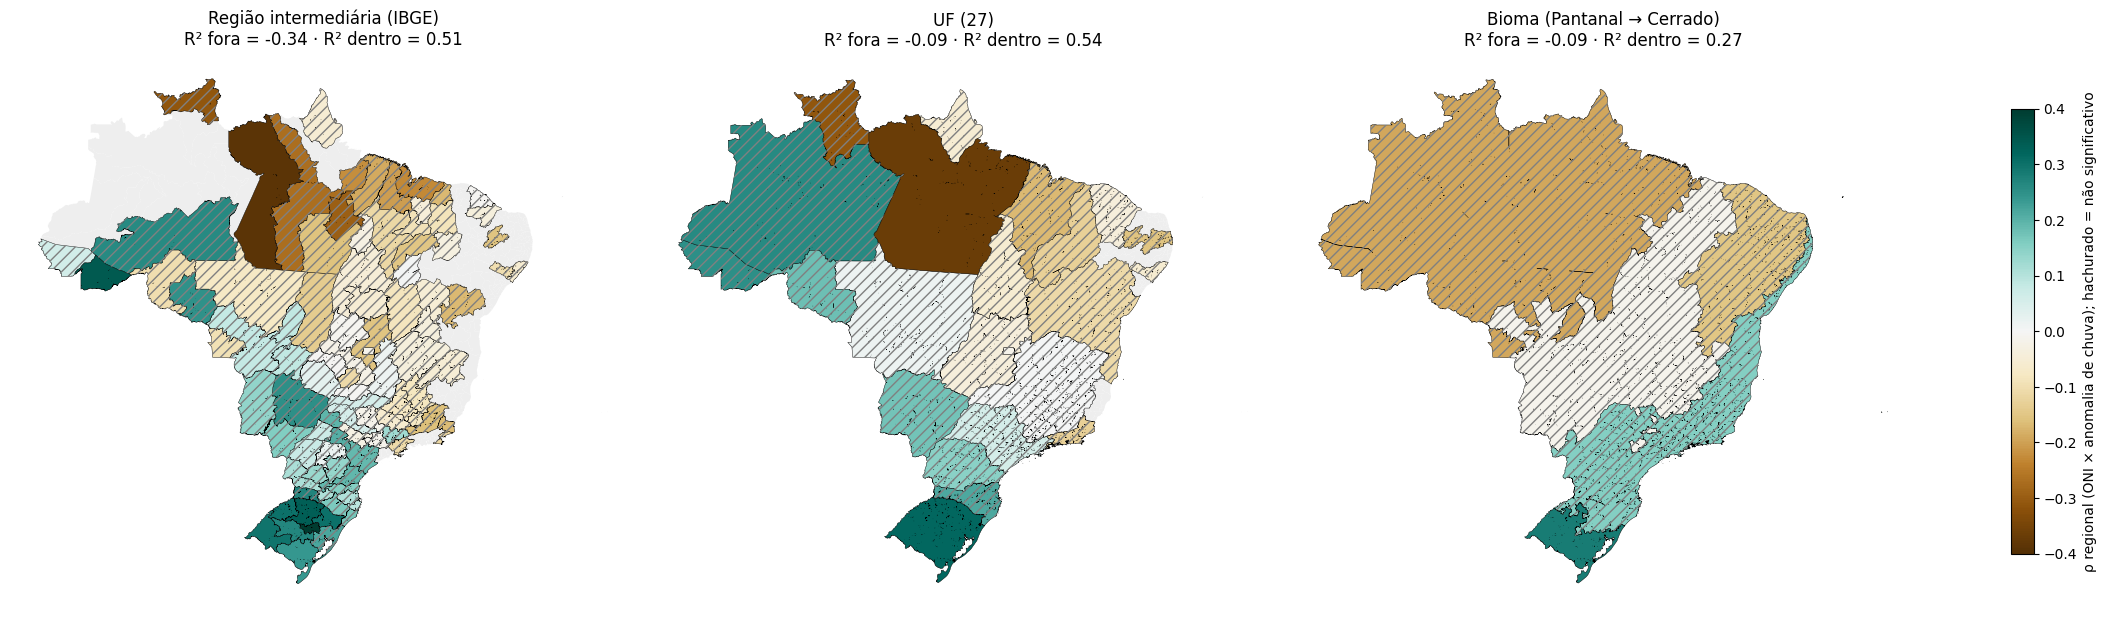

In [13]:
def tabela_regional(rotulos, mascara=None, lag=0, janela=1):
    rot = rotulos.reindex(anom.columns).dropna()
    reg = pd.DataFrame({r: anom[m].mean(axis=1) for r, m in rot.groupby(rot).groups.items()})
    if mascara is not None:
        reg = reg[mascara]
    x = enso_janela("oni", lag, janela).reindex(reg.index)
    t = pd.DataFrame([(r, *corr_neff(x, reg[r])) for r in reg.columns], columns=["regiao", "r", "p", "n_eff"]).dropna()
    t["sig"] = multipletests(t["p"], method="fdr_bh")[1] < 0.05
    return t.set_index("regiao")


fig, axes = plt.subplots(1, 3, figsize=(21, 7.5), layout="constrained")
for ax, nome in zip(axes, ["Região intermediária (IBGE)", "UF (27)", "Bioma (Pantanal → Cerrado)"]):
    reg = tabela_regional(divisoes[nome])
    g = micro.assign(regiao=micro["CD_MICRO"].map(divisoes[nome])).dissolve(by="regiao").reset_index()
    g = g.merge(reg[["r", "sig"]], left_on="regiao", right_index=True, how="left")
    micro.plot(ax=ax, color="#eeeeee", linewidth=0)
    g.dropna(subset=["r"]).plot(ax=ax, column="r", cmap="BrBG", vmin=-0.4, vmax=0.4, edgecolor="black", linewidth=0.3)
    g[g["sig"] == False].plot(ax=ax, facecolor="none", hatch="///", edgecolor="grey", linewidth=0)
    ax.set_title(f"{nome}\nR² fora = {comp.loc[nome, 'R² fora']:.2f} · R² dentro = {comp.loc[nome, 'R² dentro']:.2f}")
    ax.axis("off")
fig.colorbar(plt.cm.ScalarMappable(cmap="BrBG", norm=plt.Normalize(-0.4, 0.4)), ax=list(axes), shrink=0.6,
             label="ρ regional (ONI × anomalia de chuva); hachurado = não significativo")
plt.show()

- O padrão esperado aparece: Sul verde (mais chuva com El Niño), Norte marrom.
- Fora da amostra, todas as divisões ficam negativas: o ρ de uma microrregião sozinha é muito ruidoso (repetibilidade entre metades ≈ 0,17). O que importa é a ordem.
- Muitas regiões pequenas "decoram" o ruído: a intermediária tem R² dentro alto (0,51) e desaba fora (−0,34).
- Bioma (Pantanal no Cerrado) e UF empatam fora (−0,09). Ficamos em dúvida; seguimos com o bioma como escolha provisória (5 regiões, sentido físico) e voltamos à questão depois de achar os atrasos (seção 5).

## 4. Com quanto atraso a chuva responde

Varredura por bioma: atrasos de 0 a 12 meses × média do ONI em janelas de 1, 3 ou 6 meses. Para não escolher o atraso olhando o resultado final, a exploração usa só as safras até 2020; 2021–2025 ficam guardadas para conferir uma vez no fim. A UF (com as pequenas agrupadas) roda junto, como checagem.

In [14]:
LAGS, JANELAS = list(range(13)), [1, 3, 6]
COMBOS = [(L, w) for w in JANELAS for L in LAGS]
explora = (ano_safra <= 2020).values
verifica = ano_safra.between(2021, 2025).values
DIVS_LAG = ["Bioma (Pantanal → Cerrado)", "UF (pequenas → macrorregião)"]


def series_regionais(rotulos):
    rot = rotulos.reindex(anom.columns).dropna()
    return pd.DataFrame({r: anom[m].mean(axis=1) for r, m in rot.groupby(rot).groups.items()})


def varredura(rotulos, indice):
    reg = series_regionais(rotulos)[explora]
    lin = [dict(regiao=r, lag=L, janela=w, rho=rho, p=p)
           for L, w in COMBOS for r in reg.columns
           for rho, p, _ in [corr_neff(enso_janela(indice, L, w).reindex(reg.index), reg[r])]]
    v = pd.DataFrame(lin).dropna(subset=["rho"])
    v["sig"] = multipletests(v["p"], method="fdr_bh")[1] < 0.05
    v = v.sort_values(["regiao", "janela", "lag"])
    v["abs_rho_suav"] = v.groupby(["regiao", "janela"])["rho"].transform(lambda s: s.abs().rolling(3, center=True, min_periods=2).mean())
    return v


VARR = {(nome, ind): varredura(divisoes[nome], ind) for nome in DIVS_LAG for ind in ("oni", "soi")}
for (nome, ind), v in VARR.items():
    print(f"{nome:30s} {ind.upper()}: {v['sig'].sum()} de {len(v)} combinações passam no FDR")

Bioma (Pantanal → Cerrado)     ONI: 0 de 195 combinações passam no FDR
Bioma (Pantanal → Cerrado)     SOI: 25 de 195 combinações passam no FDR
UF (pequenas → macrorregião)   ONI: 13 de 819 combinações passam no FDR
UF (pequenas → macrorregião)   SOI: 20 de 819 combinações passam no FDR


Com o ONI e o bioma, nada passa no FDR. Só que as 195 combinações são quase repetidas (atrasos vizinhos e janelas sobrepostas medem quase o mesmo), e o FDR as trata como independentes, o que o deixa rígido demais. Dois passos:

1. **candidato por consistência:** pico de |ρ| suavizado; atrasos vizinhos com o mesmo sinal e pelo menos 2/3 do pico; SOI com sinal oposto a até 2 meses; mesmo sinal nas safras pares e ímpares;
2. **séries substitutas:** a mesma busca (máximo |ρ| nas 39 combinações) repetida com 2.000 ONIs artificiais por randomização de fase (mesmo espectro, sem ligação com a chuva) e com os 71 deslocamentos circulares de anos inteiros.

In [15]:
def candidatos(nome):
    serie = series_regionais(divisoes[nome])
    vo, vs = VARR[(nome, "oni")], VARR[(nome, "soi")]
    out = {}
    for reg, g in vo.groupby("regiao"):
        b = g.loc[g["abs_rho_suav"].idxmax()]
        L, w, rho = int(b["lag"]), int(b["janela"]), b["rho"]
        viz = g[(g["janela"] == w) & g["lag"].between(L - 1, L + 1)]
        plato = (np.sign(viz["rho"]) == np.sign(rho)).all() and viz["rho"].abs().mean() >= 2 / 3 * abs(rho)
        gs = vs[vs["regiao"] == reg]
        bs = gs.loc[gs["abs_rho_suav"].idxmax()]
        soi_ok = abs(int(bs["lag"]) - L) <= 2 and np.sign(bs["rho"]) == -np.sign(rho)
        x = enso_janela("oni", L, w).reindex(anom.index)
        rpar = corr_neff(x[explora & par], serie[reg][explora & par], 12)[0]
        rimp = corr_neff(x[explora & imp], serie[reg][explora & imp], 12)[0]
        out[reg] = dict(lag=L, janela=w, rho=rho, candidato=bool(plato and soi_ok and np.sign(rpar) == np.sign(rimp) == np.sign(rho)))
    return out


def substitutas_fase(x, n, seed):
    rng = np.random.default_rng(seed)
    F = np.fft.rfft(x - x.mean())
    out = np.empty((n, len(x)))
    for i in range(n):
        fase = rng.uniform(0, 2 * np.pi, len(F))
        fase[0] = 0
        if len(x) % 2 == 0:
            fase[-1] = 0
        out[i] = np.fft.irfft(np.abs(F) * np.exp(1j * fase), len(x)) + x.mean()
    return out


def max_rho(serie_indice, Y):
    # máximo |ρ| de Spearman entre as 39 combinações, para cada região
    X = np.column_stack([serie_indice.rolling(w, min_periods=w).mean().shift(L).reindex(Y.index).to_numpy() for L, w in COMBOS])
    out = np.full(Y.shape[1], np.nan)
    for j, reg in enumerate(Y.columns):
        y = Y[reg].to_numpy()
        ok = ~np.isnan(y) & ~np.isnan(X).any(axis=1)
        ry = rankdata(y[ok]); ry = (ry - ry.mean()) / ry.std()
        rx = rankdata(X[ok], axis=0); rx = (rx - rx.mean(0)) / rx.std(0)
        out[j] = np.abs((rx * ry[:, None]).mean(0)).max()
    return out


oni_ref = enso["oni"][(enso.index.year >= 1950) & (enso.index.year <= 2025)]
x_oni = oni_ref.to_numpy()
SUBS = {"fase": substitutas_fase(x_oni, 2000, 42),
        "deslocamento": np.array([np.roll(x_oni, 12 * k) for k in range(3, len(x_oni) // 12 - 3 + 1)])}

In [16]:
def bootstrap_safras(x, y, safras, n=2000, seed=42):
    rng = np.random.default_rng(seed)
    unicas, vals = safras.unique(), []
    for _ in range(n):
        idx = np.concatenate([np.where(safras.values == a)[0] for a in rng.choice(unicas, len(unicas))])
        xs, ys = x.iloc[idx], y.iloc[idx]
        ok = xs.notna() & ys.notna()
        if ok.sum() >= 10 and xs[ok].nunique() > 1:
            vals.append(stats.spearmanr(xs[ok], ys[ok]).statistic)
    return np.nanpercentile(vals, [2.5, 97.5])


def avaliar_atrasos(nome):
    Y = series_regionais(divisoes[nome])
    obs = max_rho(oni_ref, Y[explora])
    nulos = {f: np.array([max_rho(pd.Series(s, index=oni_ref.index), Y[explora]) for s in arr]) for f, arr in SUBS.items()}
    p = {f: (1 + (nulos[f] >= obs).sum(axis=0)) / (len(nulos[f]) + 1) for f in nulos}
    p_bh = multipletests(p["fase"], method="fdr_bh")[1]
    lin = []
    for j, (reg, c) in enumerate(candidatos(nome).items()):
        j = list(Y.columns).index(reg)
        linha = dict(região=reg, atraso=c["lag"], janela=c["janela"], ρ_exploração=c["rho"],
                     p_fase=p["fase"][j], p_desloc=p["deslocamento"][j], p_fase_BH=p_bh[j])
        if not c["candidato"]:
            lin.append({**linha, "nível": "sem padrão consistente"})
            continue
        x = enso_janela("oni", c["lag"], c["janela"]).reindex(anom.index)
        rv = corr_neff(x[verifica], Y[reg][verifica], 12)[0]
        lo_, hi_ = bootstrap_safras(x[verifica], Y[reg][verifica], ano_safra[verifica])
        r0 = corr_neff(enso_janela().reindex(anom.index)[verifica], Y[reg][verifica], 12)[0]
        repete = np.sign(rv) == np.sign(c["rho"]) and abs(rv) >= 0.10
        passa = p["fase"][j] < 0.05 and p["deslocamento"][j] < 0.05
        nivel = ("forte" if passa else "moderada") if repete else "não confirmada"
        lin.append({**linha, "ρ_2021_25": rv, "IC95_2021_25": f"[{lo_:+.2f}; {hi_:+.2f}]", "ρ_2021_25_sem_atraso": r0, "nível": nivel})
    return pd.DataFrame(lin).set_index("região")


ATRASOS = {nome: avaliar_atrasos(nome) for nome in DIVS_LAG}
ATRASOS["Bioma (Pantanal → Cerrado)"].round(3)

,atraso,janela,ρ_exploração,p_fase,p_desloc,p_fase_BH,ρ_2021_25,IC95_2021_25,ρ_2021_25_sem_atraso,nível
região,,,,,,,,,,
Amazônia,2,6,-0.341,0.087,0.083,0.217,-0.379,[-0.58; +0.17],-0.233,moderada
Caatinga,3,6,-0.222,0.261,0.306,0.327,0.061,[-0.30; +0.53],-0.041,não confirmada
Cerrado,7,3,-0.294,0.016,0.014,0.082,-0.283,[-0.57; +0.25],-0.059,forte
Mata Atlântica,0,1,0.136,0.591,0.569,0.591,NaN,NaN,NaN,sem padrão consistente
Pampa,0,1,0.216,0.189,0.194,0.316,0.411,[-0.14; +0.65],0.411,moderada


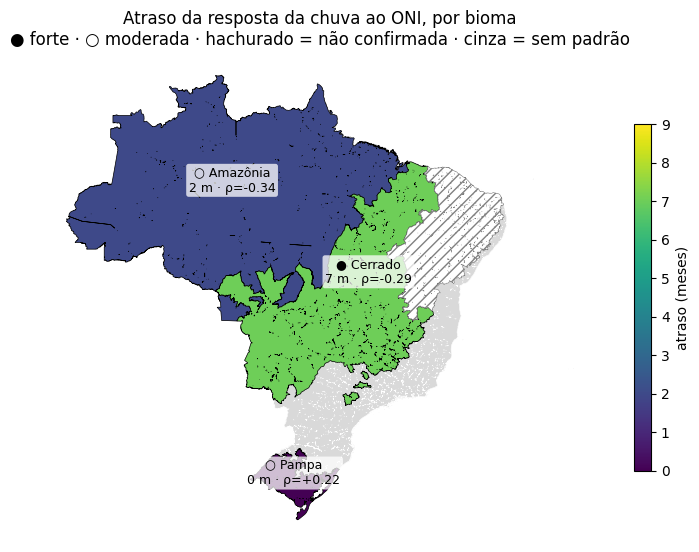

                atraso  ρ_exploração     nível
região                                        
GO                   8         -0.28     forte
MG                   8         -0.17  moderada
MT                   5         -0.41     forte
PA                   0         -0.39  moderada
resto Nordeste       5         -0.15  moderada


In [17]:
res = ATRASOS["Bioma (Pantanal → Cerrado)"]
g = micro.assign(regiao=micro["CD_MICRO"].map(BIOMA)).dissolve(by="regiao").reset_index().merge(res, left_on="regiao", right_index=True)
norma = plt.Normalize(0, 9)
fig, ax = plt.subplots(figsize=(9, 9))
micro.plot(ax=ax, color="#f2f2f2", linewidth=0)
g[g["nível"] == "sem padrão consistente"].plot(ax=ax, color="#d9d9d9", edgecolor="white", linewidth=0.4)
conf = g[g["nível"].isin(["forte", "moderada"])]
conf.plot(ax=ax, column="atraso", cmap="viridis", norm=norma, edgecolor="black", linewidth=0.5)
g[g["nível"] == "não confirmada"].plot(ax=ax, facecolor="white", hatch="///", edgecolor="grey", linewidth=0.4)
for _, r in conf.iterrows():
    pt = r.geometry.representative_point()
    ax.annotate(f"{'●' if r['nível'] == 'forte' else '○'} {r['regiao']}\n{int(r['atraso'])} m · ρ={r['ρ_exploração']:+.2f}",
                (pt.x, pt.y), ha="center", fontsize=9, bbox=dict(boxstyle="round,pad=0.2", fc="white", alpha=0.75, lw=0))
ax.set_title("Atraso da resposta da chuva ao ONI, por bioma\n● forte · ○ moderada · hachurado = não confirmada · cinza = sem padrão")
ax.axis("off")
fig.colorbar(plt.cm.ScalarMappable(cmap="viridis", norm=norma), ax=ax, shrink=0.5, label="atraso (meses)")
plt.show()

uf_res = ATRASOS["UF (pequenas → macrorregião)"]
print(uf_res.loc[uf_res["nível"].isin(["forte", "moderada"]), ["atraso", "ρ_exploração", "nível"]].round(2))

- **Cerrado: ~7 meses** (janela de 3), ρ = −0,29 na exploração. Passa no teste por substitutas (p ≈ 0,015 nas duas famílias; corrigindo para as 5 regiões testadas, 0,07–0,08) e mantém o sinal em 2021–2025 (−0,28, contra −0,06 sem atraso), embora com só 5 safras o IC cruze o zero. Na UF, MT e GO repetem o padrão (5 e 8 meses).
- **Amazônia: 2 meses** pelo critério da exploração (as substitutas apontam 3); moderada.
- **Pampa: sem atraso**; moderada. A relação mês a mês é fraca; vale olhar por eventos (seção 6).

## 5. Bioma ou UF, com o atraso

Sem atraso, bioma e UF empatavam, e o Cerrado nem respondia ao ENSO. Repetindo a comparação fora da amostra com 0, 3, 6 e 9 meses (grade fixada antes de achar os 7 meses do Cerrado), só nas safras até 2020:

                                0 m    3 m    6 m    9 m  média
Sem divisão (Brasil)         -0.007 -0.005 -0.055 -0.004 -0.018
Bioma (Pantanal → Cerrado)   -0.164 -0.118 -0.357 -0.006 -0.161
Bioma (IBGE)                 -0.160 -0.122 -0.381 -0.032 -0.174
Macrorregião (5)             -0.203 -0.149 -0.363  0.018 -0.174
Macrorregião + MATOPIBA      -0.203 -0.159 -0.388 -0.004 -0.188
UF (pequenas → macrorregião) -0.144 -0.170 -0.661 -0.237 -0.303
UF (27)                      -0.157 -0.204 -0.694 -0.235 -0.322
Região intermediária (IBGE)  -0.455 -0.446 -0.998 -0.590 -0.622


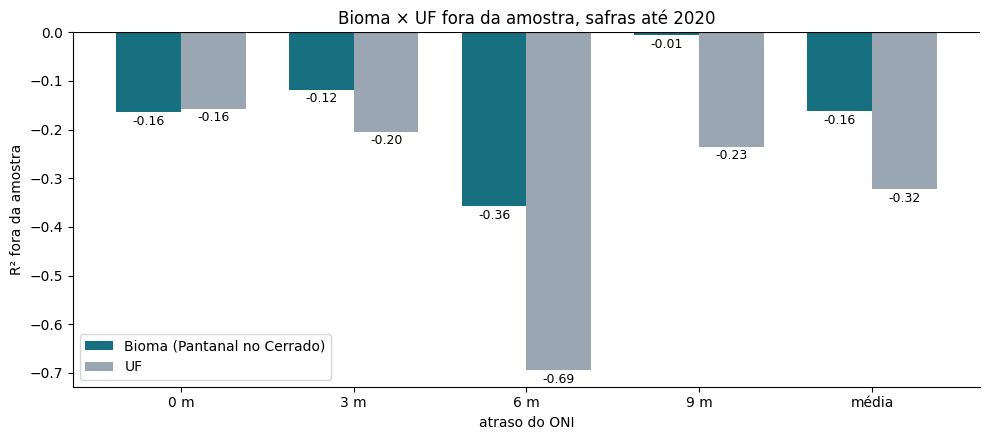

In [18]:
reav = pd.DataFrame({f"{lag} m": {nome: r2_fora(r_micro(explora & par, lag), r_micro(explora & imp, lag), rot)
                                  for nome, rot in divs_oos.items()} for lag in (0, 3, 6, 9)})
reav["média"] = reav.mean(axis=1)
print(reav.sort_values("média", ascending=False).round(3))

d = reav.loc[["Bioma (Pantanal → Cerrado)", "UF (27)"]].T
ax = d.plot.bar(figsize=(10, 4.5), color=[TEAL, "#9aa6b1"], width=0.75, rot=0)
for cont in ax.containers:
    ax.bar_label(cont, fmt="%.2f", fontsize=9, padding=2)
ax.axhline(0, color="k", lw=0.8)
ax.set_ylabel("R² fora da amostra")
ax.set_xlabel("atraso do ONI")
ax.set_title("Bioma × UF fora da amostra, safras até 2020")
ax.legend(ax.containers[:2], ["Bioma (Pantanal no Cerrado)", "UF"], loc="lower left")
plt.tight_layout()
plt.show()

Sem atraso continuam empatados (−0,16); com 3, 6 e 9 meses a UF piora bastante e o bioma fica à frente (média −0,16 contra −0,32). Macrorregião (−0,17), macrorregião + MATOPIBA (−0,19) e intermediária (−0,62) ficam abaixo. **Fica o bioma, com o Pantanal no Cerrado.** (O −0,16 sem atraso difere do −0,09 da seção 3 porque aqui só entram as safras até 2020.)

## 6. Chove mais em ano de El Niño?

Agora por eventos: cada safra 2006–2025 classificada pela fase nos seus próprios meses (regra da seção 1), sem atraso, já que um evento dura quase um ano. Chuva total da safra em % da média de cada microrregião, média por bioma.

{'La Niña': 9, 'El Niño': 7, 'neutro': 4}


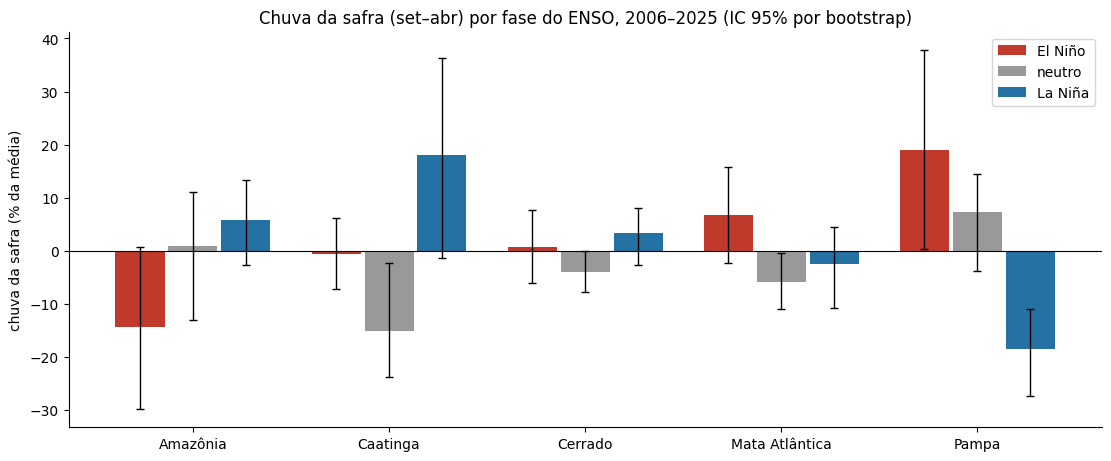

,El Niño,neutro,La Niña
Amazônia,-14.4 [-29.9; +0.8],+0.8 [-13.0; +11.0],+5.7 [-2.6; +13.4]
Caatinga,-0.6 [-7.3; +6.1],-15.1 [-23.7; -2.4],+18.0 [-1.3; +36.3]
Cerrado,+0.8 [-6.1; +7.8],-4.0 [-7.9; -0.1],+3.3 [-2.6; +8.2]
Mata Atlântica,+6.8 [-2.4; +15.8],-5.9 [-10.9; -0.4],-2.5 [-10.7; +4.6]
Pampa,+18.9 [+0.3; +37.9],+7.3 [-3.8; +14.5],-18.4 [-27.4; -10.9]


In [19]:
def anomalia_chuva(meses, min_meses):
    cm = chuva_micro[chuva_micro["mes"].isin(meses)]
    tot = cm.groupby(["CD_MICRO", "safra"]).agg(total=("chuva", "sum"), n=("chuva", "size")).reset_index()
    tot = tot[tot["n"] >= min_meses]
    tot = tot[tot.groupby("CD_MICRO")["safra"].transform("size") >= 10]
    tot["anom"] = 100 * (tot["total"] / tot.groupby("CD_MICRO")["total"].transform("mean") - 1)
    return tot.pivot(index="safra", columns="CD_MICRO", values="anom")


SAFRAS = np.arange(2006, 2026)
FASE = fase_safra(enso["oni"].dropna().to_timestamp()).reindex(SAFRAS)
print(FASE.value_counts().to_dict())

chuva_safra = anomalia_chuva(MESES_SAFRA, 7)
rot = BIOMA.reindex([c for c in chuva_safra.columns if c in anom.columns]).dropna()
chuva_bioma = pd.DataFrame({b: chuva_safra[m].mean(axis=1) for b, m in rot.groupby(rot).groups.items()}).reindex(SAFRAS)

rng = np.random.default_rng(42)
fig, ax = plt.subplots(figsize=(11, 4.5), layout="constrained")
resumo = {}
for k_, f in enumerate(FASES_CORES):
    y = [chuva_bioma.loc[FASE == f, b].dropna().to_numpy() for b in chuva_bioma.columns]
    med = np.array([v.mean() for v in y])
    ic = np.array([np.percentile([rng.choice(v, len(v)).mean() for _ in range(5000)], [2.5, 97.5]) for v in y])
    resumo[f] = [f"{m_:+.1f} [{a:+.1f}; {b:+.1f}]" for m_, (a, b) in zip(med, ic)]
    x = np.arange(len(y)) + (k_ - 1) * 0.27
    ax.bar(x, med, width=0.25, color=FASES_CORES[f], label=f)
    ax.errorbar(x, med, yerr=[med - ic[:, 0], ic[:, 1] - med], fmt="none", ecolor="black", capsize=3, lw=1)
ax.axhline(0, color="black", lw=0.8)
ax.set_xticks(range(len(chuva_bioma.columns)), chuva_bioma.columns)
ax.set_ylabel("chuva da safra (% da média)")
ax.set_title("Chuva da safra (set–abr) por fase do ENSO, 2006–2025 (IC 95% por bootstrap)")
ax.legend()
plt.show()
pd.DataFrame(resumo, index=chuva_bioma.columns)

- **Pampa:** −18% na La Niña (IC longe do zero) e +19% no El Niño (IC de +0,3 a +38: encosta no zero). A correlação mês a mês do Pampa era fraca, mas por eventos é o sinal mais forte: o efeito está nos episódios.
- **Amazônia:** −14% no El Niño, com IC encostando no zero.
- **Cerrado:** quase nada na safra inteira, porque o sinal se inverte dentro dela (setembro mais chuvoso com El Niño; dezembro a abril, mais seco).
- Com 7, 9 e 4 safras por fase, tudo aqui é frágil.

## 7. Do clima ao rendimento

Rendimento da soja da PAM (IBGE, Tabela 1612), produção ÷ área colhida somadas por microrregião (município pelo centroide). O rendimento sobe com a tecnologia, então cada safra é comparada com uma tendência LOWESS robusta de 25 anos (suave o bastante para não apagar secas de vários anos); a anomalia é em %. Como a chuva vem do INMET, a janela é 2006–2025.

In [20]:
ARQ_PAM = RAW / "pam_soja_municipio_1974_2025.csv"
if not ARQ_PAM.exists():                    # baixa da API do SIDRA (tabela 1612, soja), ano a ano (alguns minutos)
    import time
    import sidrapy
    partes = []
    for a in range(1974, 2026):
        for tentativa in range(3):
            try:
                t = sidrapy.get_table(table_code="1612", territorial_level="6", ibge_territorial_code="all",
                                      variable="214,216", classifications={"81": "2713"}, period=str(a)).iloc[1:]
                partes.append(t[["D1C", "D1N", "D2C", "D3C", "V"]])
                break
            except Exception as e:
                print(f"{a}: tentativa {tentativa + 1} falhou ({e})")
                time.sleep(3)
    pam = pd.concat(partes)
    pam["V"] = pd.to_numeric(pam["V"], errors="coerce")
    pam = pam.pivot_table(index=["D1C", "D1N", "D2C"], columns="D3C", values="V", aggfunc="first").reset_index()
    pam.rename(columns={"D1C": "codigo", "D1N": "nome", "D2C": "ano", "214": "producao_t", "216": "area_colhida_ha"}).to_csv(ARQ_PAM, index=False)

mun = pd.read_csv(ARQ_PAM, dtype={"codigo": str})
municipios = geobr.read_municipality(year=2020, show_progress=False)
cent = municipios.to_crs(5880)
cent["geometry"] = cent.centroid
j = gpd.sjoin(cent.to_crs(micro.crs)[["code_muni", "geometry"]], micro[["CD_MICRO", "geometry"]], predicate="within")
muni_micro = pd.DataFrame({"codigo": j["code_muni"].astype(int).astype(str), "CD_MICRO": j["CD_MICRO"]})

r = (mun.merge(muni_micro, on="codigo").groupby(["CD_MICRO", "ano"])[["producao_t", "area_colhida_ha"]]
        .sum(min_count=1).reset_index().dropna())
r = r[r["area_colhida_ha"] >= 100].copy()
r["rend"] = r["producao_t"] * 1000 / r["area_colhida_ha"]
r = r[r["rend"].between(1, 6000)]
r = r[r.groupby("CD_MICRO")["ano"].transform("size") >= 15]


def tendencia(g):
    a, y = g["ano"].to_numpy(float), g["rend"].to_numpy(float)
    return pd.Series(lowess(y, a, frac=min(1.0, 25 / (a.max() - a.min() + 1)), it=3, return_sorted=False), index=g.index)


r["anom"] = 100 * (r["rend"] / r.groupby("CD_MICRO", group_keys=False)[["ano", "rend"]].apply(tendencia) - 1)
REND_TODAS = r.pivot(index="ano", columns="CD_MICRO", values="anom")
AREA = r.groupby("CD_MICRO")["area_colhida_ha"].mean()

pac["safra"] = np.where(pac["mes"] >= 9, pac["ano"] + 1, pac["ano"])
o = pac[pac["mes"].isin(MESES_SAFRA)].groupby("safra")["oni"].agg(["mean", "size"])
ONI_SAFRA = o.loc[o["size"] == 8, "mean"]                       # ONI médio de set–abr

SUBPER = {"set–nov": [9, 10, 11], "dez–fev": [12, 1, 2], "mar–abr": [3, 4]}
CHUVA = {"safra": chuva_safra.reindex(SAFRAS), **{k: anomalia_chuva(m, len(m)).reindex(SAFRAS) for k, m in SUBPER.items()}}
REND, X_ONI = REND_TODAS.reindex(SAFRAS), ONI_SAFRA.reindex(SAFRAS)

comum = REND.columns.intersection(CHUVA["safra"].columns)
n_par = (REND[comum].notna() & CHUVA["safra"][comum].notna()).sum()
MICROS = n_par[n_par >= 10].index
UF = micro_idx["abbrev_state"]
REGIOES = {"Amazônia": MICROS[BIOMA.reindex(MICROS).to_numpy() == "Amazônia"],
           "Cerrado": MICROS[BIOMA.reindex(MICROS).to_numpy() == "Cerrado"],
           **{f"UF {u}": MICROS[UF.reindex(MICROS).to_numpy() == u] for u in ["MT", "GO"]},
           "MATOPIBA (MA + PI)": MICROS[UF.reindex(MICROS).isin(["MA", "PI"]).to_numpy()],
           "Pampa": MICROS[BIOMA.reindex(MICROS).to_numpy() == "Pampa"],
           **{f"UF {u}": MICROS[UF.reindex(MICROS).to_numpy() == u] for u in ["PR", "RS"]}}
print(f"{len(MICROS)} microrregiões com chuva e rendimento em ≥ 10 safras:", {k: len(v) for k, v in REGIOES.items()})

153 microrregiões com chuva e rendimento em ≥ 10 safras: {'Amazônia': 17, 'Cerrado': 60, 'UF MT': 16, 'UF GO': 12, 'MATOPIBA (MA + PI)': 8, 'Pampa': 16, 'UF PR': 17, 'UF RS': 25}


Análise em painel (microrregião × safra), com Spearman. Como uma seca atinge várias microrregiões ao mesmo tempo, os testes reamostram **safras inteiras**: permutação para o p, bootstrap para o IC. Para saber quanto da relação ENSO × rendimento passa por uma variável do clima, uso a correlação parcial: **fração = 1 − parcial ÷ total**. É uma decomposição descritiva, não variância explicada (pode passar de 100%).

In [21]:
RNG = np.random.default_rng(42)
PERMS = np.array([RNG.permutation(len(SAFRAS)) for _ in range(5000)])
BOOTS = RNG.integers(0, len(SAFRAS), size=(2000, len(SAFRAS)))


def mat(x, micros):
    return np.repeat(x.to_numpy(float)[:, None], len(micros), axis=1) if isinstance(x, pd.Series) else x.reindex(columns=micros).to_numpy(float)


def rho(a, b):
    a, b = a.ravel(), b.ravel()
    ok = ~(np.isnan(a) | np.isnan(b))
    return float(np.corrcoef(rankdata(a[ok]), rankdata(b[ok]))[0, 1]) if ok.sum() >= 10 else np.nan


def parcial(y, x, z):
    y, x, z = y.ravel(), x.ravel(), z.ravel()
    ok = ~(np.isnan(y) | np.isnan(x) | np.isnan(z))
    if ok.sum() < 10:
        return np.nan
    c = np.corrcoef(np.vstack([rankdata(y[ok]), rankdata(x[ok]), rankdata(z[ok])]))
    return float((c[0, 1] - c[0, 2] * c[1, 2]) / np.sqrt((1 - c[0, 2] ** 2) * (1 - c[1, 2] ** 2)))


def frac(total, parc):
    return 1 - parc / total if abs(total) > 1e-9 else np.nan


def p_perm(X, Y):
    obs = rho(X, Y)
    return float((1 + np.sum([abs(rho(X[p], Y)) >= abs(obs) for p in PERMS])) / (1 + len(PERMS)))


def fracao(Xo, Y, Z, ic=False):
    # total e parcial na mesma amostra (pares com Z disponível); IC por bootstrap de safras
    f = lambda a, b, c: frac(rho(a, np.where(np.isnan(c), np.nan, b)), parcial(np.where(np.isnan(c), np.nan, b), a, c))
    fr = f(Xo, Y, Z)
    if not ic:
        return fr
    bs = np.array([f(Xo[b], Y[b], Z[b]) for b in BOOTS])
    return fr, np.nanpercentile(bs, 2.5), np.nanpercentile(bs, 97.5)


def media_regional(df, micros):
    w = AREA.reindex(micros)
    v = df.reindex(columns=micros)
    return (v * w).sum(axis=1, min_count=1) / v.notna().mul(w).sum(axis=1).replace(0, np.nan)

In [22]:
# os dois elos, por subperíodo, no Pampa e no Cerrado
elos = {}
for reg in ["Pampa", "Cerrado"]:
    m = REGIOES[reg]
    elos[reg] = pd.DataFrame({"ENSO → chuva": {k: rho(mat(X_ONI, m), mat(v, m)) for k, v in CHUVA.items()},
                              "chuva → rendimento": {k: rho(mat(v, m), mat(REND, m)) for k, v in CHUVA.items()}})
print(pd.concat(elos, axis=1).round(2))

# quanto da relação ENSO × rendimento passa pela chuva da safra
lin = []
for reg, m in REGIOES.items():
    Xo, Y, C = mat(X_ONI, m), mat(REND, m), mat(CHUVA["safra"], m)
    Yc = np.where(np.isnan(C), np.nan, Y)
    lin.append({"região": reg, "ρ ENSO → rend.": rho(Xo, Yc), "p": p_perm(Xo, Yc), "fração pela chuva": fracao(Xo, Y, C)})
pd.DataFrame(lin).set_index("região").round(3)

               Pampa                         Cerrado                   
        ENSO → chuva chuva → rendimento ENSO → chuva chuva → rendimento
safra           0.59               0.21        -0.07               0.09
set–nov         0.64              -0.04         0.05              -0.00
dez–fev         0.37               0.45        -0.16               0.16
mar–abr         0.24               0.11        -0.01              -0.06


,ρ ENSO → rend.,p,fração pela chuva
região,,,
Amazônia,-0.165,0.124,0.038
Cerrado,-0.316,0.009,0.013
UF MT,-0.442,0.004,0.006
UF GO,-0.302,0.037,0.040
MATOPIBA (MA + PI),-0.461,0.001,0.029
Pampa,-0.051,0.752,-3.377
UF PR,0.056,0.795,0.225
UF RS,0.045,0.797,4.396


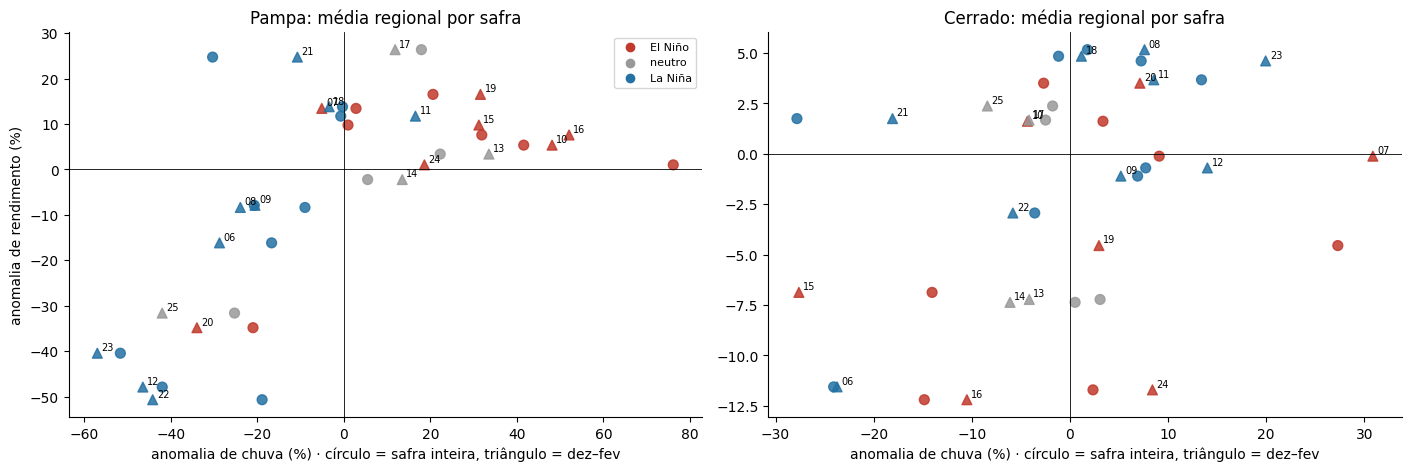

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.6), layout="constrained")
for ax, reg in zip(axes, ["Pampa", "Cerrado"]):
    m = REGIOES[reg]
    t = pd.DataFrame({"rend": media_regional(REND, m), "safra": media_regional(CHUVA["safra"], m),
                      "dez–fev": media_regional(CHUVA["dez–fev"], m), "fase": FASE})
    for col, mk in [("safra", "o"), ("dez–fev", "^")]:
        ax.scatter(t[col], t["rend"], c=t["fase"].map(FASES_CORES), marker=mk, s=50, alpha=0.85)
    for s_, l in t.iterrows():
        ax.annotate(str(s_)[2:], (l["dez–fev"], l["rend"]), fontsize=7, xytext=(3, 2), textcoords="offset points")
    ax.axhline(0, color="k", lw=0.6)
    ax.axvline(0, color="k", lw=0.6)
    ax.set_title(f"{reg}: média regional por safra")
    ax.set_xlabel("anomalia de chuva (%) · círculo = safra inteira, triângulo = dez–fev")
axes[0].set_ylabel("anomalia de rendimento (%)")
for f, c_ in FASES_CORES.items():
    axes[0].scatter([], [], c=c_, label=f)
axes[0].legend(fontsize=8)
plt.show()

- **Sul:** o ENSO mexe sobretudo na chuva de set–nov, que pouco pesa no rendimento; o rendimento acompanha a chuva de dez–fev, em qualquer fase. Por isso o ENSO sozinho quase não aparece no rendimento do Pampa (ρ ≈ 0).
- **Centro-Norte:** o El Niño se associa a rendimento menor (Cerrado ρ = −0,32, MT −0,44, MATOPIBA −0,46), mas quase nada disso passa pela chuva medida (fração 0,01 no Cerrado, 0,01 no MT, 0,03 no MATOPIBA). Nas dispersões do Cerrado, safras de El Niño rendem menos mesmo com chuva normal.

Se não é a chuva, o candidato óbvio é a temperatura.

## 8. E o calor?

Temperatura máxima das mesmas estações, média por microrregião e período, **sem a tendência linear** de cada microrregião (o ONI e a temperatura subiram juntos entre 2004 e 2020, o que inflaria a correlação).

In [24]:
mt = clima.dropna(subset=["temp_max"]).groupby(["codigo_estacao", "mes_ref"])["temp_max"].agg(tmax="mean", dias="count").reset_index()
mt = mt[mt["dias"] >= 0.8 * mt["mes_ref"].dt.days_in_month]
tmax_micro = mt.merge(mapa[["codigo_estacao", "CD_MICRO"]], on="codigo_estacao").groupby(["CD_MICRO", "mes_ref"])["tmax"].mean().reset_index()
tmax_micro["mes"] = tmax_micro["mes_ref"].dt.month
tmax_micro["safra"] = np.where(tmax_micro["mes"] >= 9, tmax_micro["mes_ref"].dt.year + 1, tmax_micro["mes_ref"].dt.year)


def anomalia_tmax(meses, min_meses):
    t = tmax_micro[tmax_micro["mes"].isin(meses)].groupby(["CD_MICRO", "safra"]).agg(v=("tmax", "mean"), n=("tmax", "size")).reset_index()
    t = t[t["n"] >= min_meses]
    t = t[t.groupby("CD_MICRO")["safra"].transform("size") >= 10]
    t["anom"] = t.groupby("CD_MICRO", group_keys=False)[["safra", "v"]].apply(
        lambda g: g["v"] - np.polyval(np.polyfit(g["safra"].to_numpy(float), g["v"].to_numpy(float), 1), g["safra"]))
    return t.pivot(index="safra", columns="CD_MICRO", values="anom").reindex(SAFRAS)


TMAX = {"safra": anomalia_tmax(MESES_SAFRA, 7), "dez–fev": anomalia_tmax([12, 1, 2], 3)}
pd.DataFrame({(per, elo): {reg: rho(*((mat(X_ONI, m), mat(T, m)) if elo == "ENSO → Tmax" else (mat(T, m), mat(REND, m))))
                             for reg, m in REGIOES.items()}
              for per, T in TMAX.items() for elo in ("ENSO → Tmax", "Tmax → rend.")}).round(2)

safra                  dez–fev             
                   ENSO → Tmax Tmax → rend. ENSO → Tmax Tmax → rend.
Amazônia                  0.33        -0.13        0.52        -0.13
Cerrado                   0.34        -0.22        0.54        -0.38
UF MT                     0.23        -0.23        0.44        -0.31
UF GO                     0.35        -0.13        0.67        -0.40
MATOPIBA (MA + PI)        0.50        -0.20        0.59        -0.28
Pampa                    -0.17        -0.31       -0.23        -0.41
UF PR                     0.22        -0.15        0.29        -0.40
UF RS                    -0.12        -0.34       -0.16        -0.43

O El Niño esquenta o Centro-Norte (Tmax da safra, ρ ≈ +0,4), e mais em dez–fev (Cerrado 0,54, GO 0,67). Dez–fev quente reduz o rendimento (Cerrado −0,38, GO −0,40). Os dois elos existem; falta ver quanto da relação ENSO × rendimento cada variável "absorve". Para comparar de forma justa com a chuva, mesmo período (dez–fev) e mesma amostra:

In [25]:
lin = []
for reg, m in REGIOES.items():
    Xo, Y, Tm, Cm, Ts = mat(X_ONI, m), mat(REND, m), mat(TMAX["dez–fev"], m), mat(CHUVA["dez–fev"], m), mat(TMAX["safra"], m)
    fr, lo_, hi_ = fracao(Xo, Y, Tm, ic=True)
    ok = ~(np.isnan(Cm) | np.isnan(Tm))
    Yok = np.where(ok, Y, np.nan)
    lin.append({"região": reg, "calor da safra": fracao(Xo, Y, Ts), "calor dez–fev": fr, "IC95": f"[{lo_:+.2f}; {hi_:+.2f}]",
                "chuva dez–fev (mesma amostra)": fracao(Xo, Yok, np.where(ok, Cm, np.nan)),
                "calor dez–fev (mesma amostra)": fracao(Xo, Yok, np.where(ok, Tm, np.nan))})
frac_calor = pd.DataFrame(lin).set_index("região")
print("fração da relação ENSO × rendimento que passa por cada variável")
frac_calor.round(2)

fração da relação ENSO × rendimento que passa por cada variável


,calor da safra,calor dez–fev,IC95,chuva dez–fev (mesma amostra),calor dez–fev (mesma amostra)
região,,,,,
Amazônia,0.21,0.27,[-0.99; +1.46],0.01,0.27
Cerrado,0.17,0.54,[+0.29; +0.93],0.06,0.54
UF MT,0.07,0.19,[-0.07; +0.43],-0.00,0.19
UF GO,0.08,0.73,[+0.30; +1.77],0.12,0.73
MATOPIBA (MA + PI),0.08,0.15,[-0.08; +0.47],0.01,0.15
Pampa,-1.19,-2.35,[-12.63; +11.41],-4.45,-2.35
UF PR,-0.65,-7.19,[-11.19; +10.25],1.13,-7.19
UF RS,0.95,1.63,[-5.75; +7.27],4.14,1.63


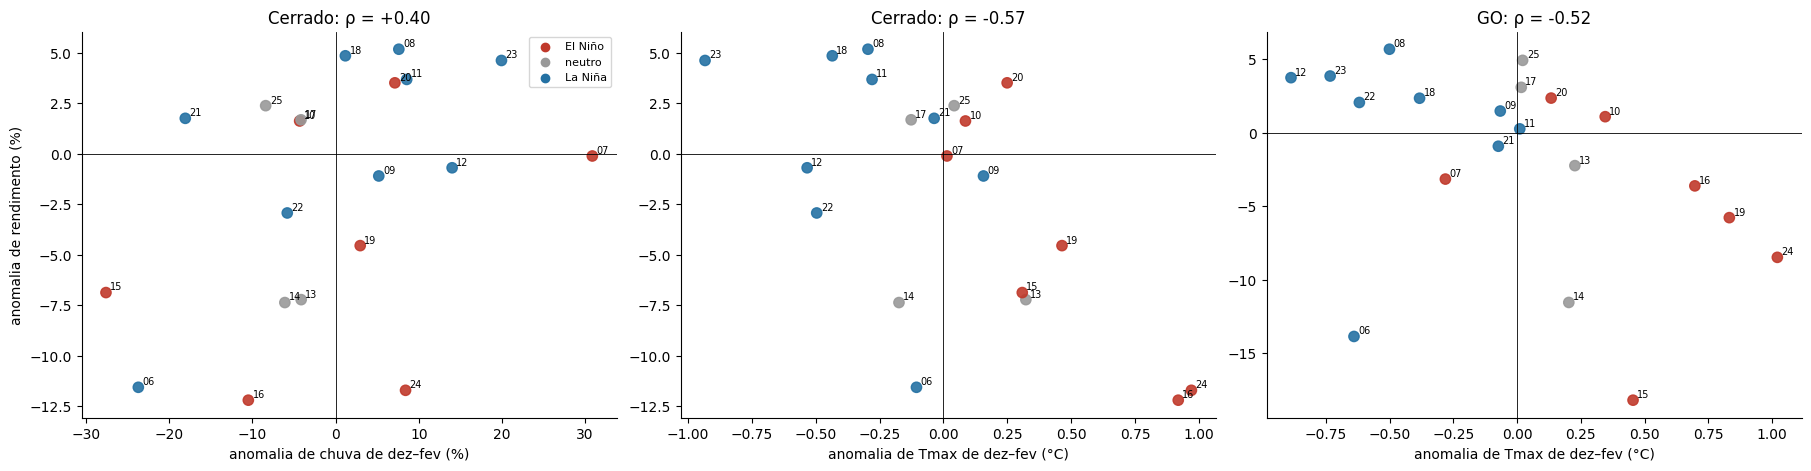

In [26]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4.6), layout="constrained")
for ax, (reg, var, rotulo) in zip(axes, [("Cerrado", CHUVA["dez–fev"], "chuva de dez–fev (%)"),
                                         ("Cerrado", TMAX["dez–fev"], "Tmax de dez–fev (°C)"),
                                         ("UF GO", TMAX["dez–fev"], "Tmax de dez–fev (°C)")]):
    m = REGIOES[reg]
    t = pd.DataFrame({"x": media_regional(var, m), "y": media_regional(REND, m), "fase": FASE}).dropna()
    ax.scatter(t["x"], t["y"], c=t["fase"].map(FASES_CORES), s=55, alpha=0.9)
    for s_, l in t.iterrows():
        ax.annotate(str(s_)[2:], (l["x"], l["y"]), fontsize=7, xytext=(3, 2), textcoords="offset points")
    ax.axhline(0, color="k", lw=0.6)
    ax.axvline(0, color="k", lw=0.6)
    ax.set_title(f"{reg.replace('UF ', '')}: ρ = {t['x'].corr(t['y'], method='spearman'):+.2f}")
    ax.set_xlabel(f"anomalia de {rotulo}")
axes[0].set_ylabel("anomalia de rendimento (%)")
for f, c_ in FASES_CORES.items():
    axes[0].scatter([], [], c=c_, label=f)
axes[0].legend(fontsize=8)
plt.show()

- Com a chuva de dez–fev, as safras de El Niño se espalham; com o calor de dez–fev, elas se juntam embaixo à direita (mais quente, rendimento menor).
- O calor de dez–fev absorve cerca de metade da relação no Cerrado (54%, IC 29–93%) e três quartos em GO (73%, IC 30–177%); no MT (19%) e no MATOPIBA (15%) o IC cruza o zero. A chuva de dez–fev, na mesma amostra: 6%, 12%, 0% e 1%.
- **Cautela:** a hipótese que eu tinha antes de rodar era o calor da safra inteira, que explicou pouco (17% no Cerrado). Dez–fev foi destacado depois de olhar os dados, então isso precisa ser confirmado fora desta amostra.

## 9. Confirmação com outra fonte e outros anos

Hipóteses e critério registrados antes de baixar os dados (D-15). Fonte: CPC Global Unified Temperature (NOAA), Tmax diária em grade de 0,5°, 1980–2025; a Tmax de cada microrregião é a média das células dentro dela (ou a mais próxima).
- **Teste A, safras 1981–2005:** anos que não participaram da escolha de dez–fev. Pede El Niño → calor > 0 e calor → rendimento < 0 no Cerrado e em GO.
- **Teste B, safras 2006–2025 com a grade:** mesmos anos, outra medição. Pede fração pelo calor com IC acima de zero.

A grade interpola a rede mundial de estações, que inclui estações brasileiras: a independência em relação ao INMET é parcial.

In [27]:
CPC = RAW / "cpc_tmax"
CPC.mkdir(parents=True, exist_ok=True)
for a in range(1980, 2026):
    out = CPC / f"tmax_br_{a}.npz"
    if out.exists():
        continue
    f = CPC / f"tmax.{a}.nc"
    subprocess.run(["curl", "-sS", "-f", "--retry", "4", "-o", str(f),
                    f"https://downloads.psl.noaa.gov/Datasets/cpc_global_temp/tmax.{a}.nc"], check=True)
    with netCDF4.Dataset(f) as ds:
        la_, lo_ = ds["lat"][:], ds["lon"][:]
        il, jl = np.where((la_ >= -34.5) & (la_ <= 6.5))[0], np.where((lo_ >= 285.5) & (lo_ <= 326.5))[0]
        v = ds["tmax"][:, il.min():il.max() + 1, jl.min():jl.max() + 1]
        t = netCDF4.num2date(ds["time"][:], ds["time"].units, only_use_cftime_datetimes=False)
        np.savez_compressed(out, tmax=np.ma.filled(v.astype("float32"), np.nan), lat=np.asarray(la_[il.min():il.max() + 1]),
                            lon=np.asarray(lo_[jl.min():jl.max() + 1]) - 360, data=np.array([np.datetime64(str(x)[:10]) for x in t]))
    f.unlink()

arqs = [np.load(CPC / f"tmax_br_{a}.npz") for a in range(1980, 2026)]
grade = np.concatenate([a["tmax"] for a in arqs])
datas = pd.DatetimeIndex(np.concatenate([a["data"] for a in arqs]))
glon, glat = np.meshgrid(arqs[0]["lon"], arqs[0]["lat"])
pts = gpd.GeoDataFrame({"cel": np.arange(glon.size)}, geometry=gpd.points_from_xy(glon.ravel(), glat.ravel()), crs=micro.crs)
pts = pts[np.isfinite(grade).mean(axis=0).ravel() > 0.5]
celulas = gpd.sjoin(pts, micro[["CD_MICRO", "geometry"]], predicate="within").groupby("CD_MICRO")["cel"].apply(list).to_dict()
sem = micro[~micro["CD_MICRO"].isin(celulas)]
for cd, c in zip(sem["CD_MICRO"], sem.to_crs(5880).centroid.to_crs(micro.crs)):
    celulas[cd] = [int(pts["cel"].iloc[int(np.argmin(((pts.geometry.x - c.x) ** 2 + (pts.geometry.y - c.y) ** 2).to_numpy()))])]
flat = grade.reshape(len(datas), -1)
TMAX_DIA = pd.DataFrame({cd: np.nanmean(flat[:, c], axis=1) for cd, c in celulas.items()}, index=datas)
del flat, grade
print(f"CPC: {datas.min().date()} a {datas.max().date()} | {len(celulas)} microrregiões ({len(sem)} pela célula mais próxima)")

In [28]:
d = TMAX_DIA.copy()
d["safra"] = np.where(d.index.month >= 9, d.index.year + 1, d.index.year)
dias = (d.index.to_numpy() - pd.to_datetime((d["safra"] - 1).astype(str) + "-09-01").to_numpy()) / np.timedelta64(1, "D")
PERIODOS = {"dez–fev": np.isin(d.index.month, [12, 1, 2]),
            "floração–enchimento": (dias >= 90) & (dias <= 129),          # janela usada no pipeline
            "safra": np.isin(d.index.month, MESES_SAFRA)}
SAFRAS_A, SAFRAS_B = np.arange(1981, 2006), SAFRAS


def anomalia_cpc(mascara, safras):
    sub = d[mascara]
    media = sub.groupby("safra").mean().drop(columns="safra", errors="ignore")
    validos = sub.drop(columns="safra").notna().groupby(sub["safra"]).sum()
    tab = media.where(validos.ge(0.8 * sub.groupby("safra").size(), axis=0)).reindex(safras)
    x = tab.index.to_numpy(float)
    out = pd.DataFrame(index=tab.index, columns=tab.columns, dtype=float)
    for c in tab.columns:
        y = tab[c].to_numpy(float)
        ok = np.isfinite(y)
        if ok.sum() >= 10:
            out[c] = y - np.polyval(np.polyfit(x[ok], y[ok], 1), x)
    return out


TA = {k: anomalia_cpc(m, SAFRAS_A) for k, m in PERIODOS.items()}
TB = {k: anomalia_cpc(m, SAFRAS_B) for k, m in PERIODOS.items()}
nA = (REND_TODAS.reindex(SAFRAS_A).notna() & TA["dez–fev"].reindex(columns=REND_TODAS.columns).notna()).sum()
MICROS_A = nA[nA >= 10].index


def regioes_conf(micros):
    micros = pd.Index(micros)
    return {"Cerrado": micros[BIOMA.reindex(micros).to_numpy() == "Cerrado"], "GO": micros[UF.reindex(micros).to_numpy() == "GO"],
            "MT": micros[UF.reindex(micros).to_numpy() == "MT"], "MATOPIBA (MA + PI)": micros[UF.reindex(micros).isin(["MA", "PI"]).to_numpy()],
            "Amazônia": micros[BIOMA.reindex(micros).to_numpy() == "Amazônia"]}

In [29]:
rng_c = np.random.default_rng(42)


def mat_s(x, micros, safras):
    return (np.repeat(x.reindex(safras).to_numpy(float)[:, None], len(micros), axis=1) if isinstance(x, pd.Series)
            else x.reindex(index=safras, columns=micros).to_numpy(float))


def p_perm_c(X, Y):
    obs = rho(X, Y)
    nul = np.array([rho(X[rng_c.permutation(len(X))], Y) for _ in range(5000)])
    return float((1 + np.sum(np.abs(nul) >= abs(obs))) / (1 + len(nul)))


def cadeia_c(Xo, Y, T):
    f = lambda a, b, c: frac(rho(a, np.where(np.isfinite(c), b, np.nan)), parcial(np.where(np.isfinite(c), b, np.nan), a, c))
    Yt = np.where(np.isfinite(T), Y, np.nan)
    tot, fr = rho(Xo, Yt), f(Xo, Y, T)
    bs = np.array([f(Xo[b], Y[b], T[b]) for b in rng_c.integers(0, len(Xo), size=(2000, len(Xo)))])
    return tot, p_perm_c(Xo, Yt), fr, np.nanpercentile(bs, 2.5), np.nanpercentile(bs, 97.5)


def teste(T, micros, safras, com_p_elos):
    lin = []
    for per in PERIODOS:
        for reg, m in regioes_conf(micros).items():
            if len(m) < 3:
                continue
            Xo, Tt, Y = mat_s(ONI_SAFRA, m, safras), mat_s(T[per], m, safras), mat_s(REND_TODAS, m, safras)
            linha = {"período": per, "região": reg, "micros": len(m), "ENSO → Tmax": rho(Xo, Tt)}
            if com_p_elos:
                linha["p1"] = p_perm_c(Xo, Tt)
            linha["Tmax → rend."] = rho(Tt, Y)
            if com_p_elos:
                linha["p2"] = p_perm_c(Tt, Y)
            tot, pt, fr, lo_, hi_ = cadeia_c(Xo, Y, Tt)
            lin.append({**linha, "ρ ENSO → rend.": tot, "p total": pt, "fração calor": fr, "IC95": f"[{lo_:+.2f}; {hi_:+.2f}]", "IC > 0": lo_ > 0})
    return pd.DataFrame(lin)


TAB_A = teste(TA, MICROS_A, SAFRAS_A, com_p_elos=True)
TAB_B = teste(TB, MICROS, SAFRAS_B, com_p_elos=False)
print("Teste A · 1981–2005")
print(TAB_A[TAB_A["região"].isin(["Cerrado", "GO"])].round(3).to_string(index=False))
print("\nTeste B · 2006–2025, dez–fev")
TAB_B[TAB_B["período"] == "dez–fev"].round(3)

Teste A · 1981–2005
            período  região  micros  ENSO → Tmax    p1  Tmax → rend.    p2  ρ ENSO → rend.  p total  fração calor           IC95  IC > 0
            dez–fev Cerrado      80        0.234 0.082        -0.097 0.079          -0.072    0.359         0.288 [-1.23; +2.15]   False
            dez–fev      GO      18        0.112 0.528         0.019 0.840           0.023    0.847         0.100 [-2.15; +1.90]   False
floração–enchimento Cerrado      80        0.395 0.004         0.044 0.483          -0.072    0.358        -0.345 [-4.36; +4.86]   False
floração–enchimento      GO      18        0.396 0.027         0.124 0.219           0.023    0.819         2.229 [-8.21; +8.28]   False
              safra Cerrado      80        0.339 0.014        -0.071 0.206          -0.072    0.345         0.289 [-2.21; +2.63]   False
              safra      GO      18        0.319 0.067        -0.000 0.997           0.023    0.835        -0.061 [-3.71; +4.08]   False

Teste B · 2006–2025,

,período,região,micros,ENSO → Tmax,Tmax → rend.,ρ ENSO → rend.,p total,fração calor,IC95,IC > 0
0,dez–fev,Cerrado,60,0.376,-0.332,-0.282,0.020,0.365,[+0.18; +1.13],True
1,dez–fev,GO,12,0.557,-0.197,-0.299,0.042,0.224,[-0.33; +0.89],False
2,dez–fev,MT,16,0.275,-0.304,-0.369,0.015,0.154,[-0.09; +0.54],False
3,dez–fev,MATOPIBA (MA + PI),8,0.256,-0.234,-0.378,0.002,0.105,[-0.03; +0.35],False
4,dez–fev,Amazônia,17,0.265,-0.135,-0.147,0.150,0.201,[-1.00; +1.62],False


         A: ENSO → calor > 0  A: calor → rend. < 0  B: fração com IC > 0
região                                                                  
Cerrado                False                 False                  True
GO                     False                 False                 False 

1 de 6 condições atendidas


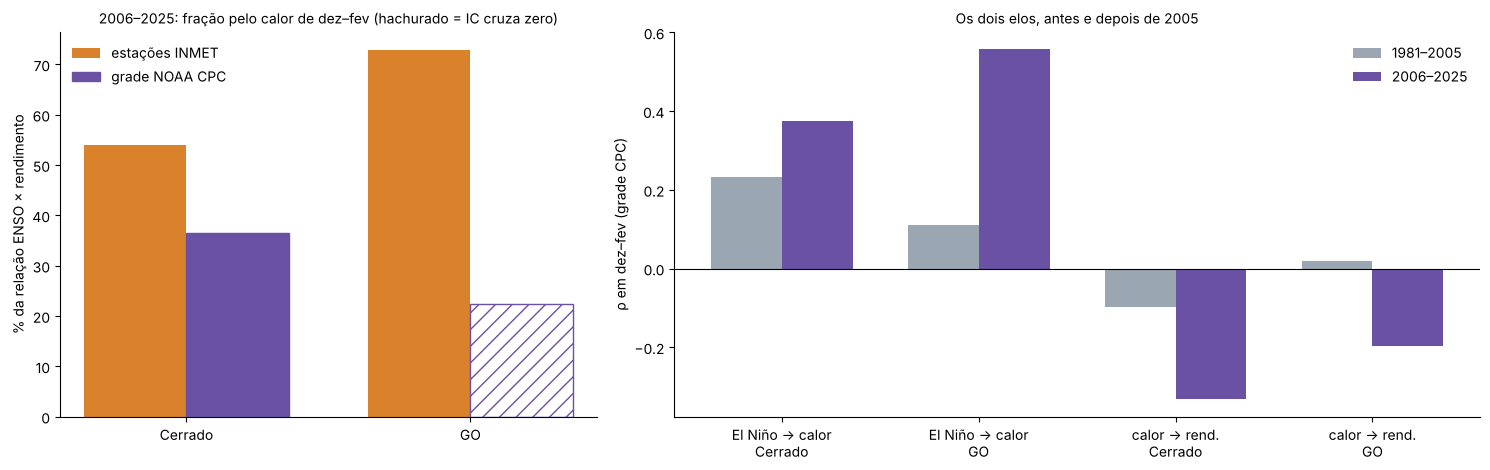

In [30]:
a = TAB_A[TAB_A["período"] == "dez–fev"].set_index("região").loc[["Cerrado", "GO"]]
b = TAB_B[TAB_B["período"] == "dez–fev"].set_index("região").loc[["Cerrado", "GO"]]
cond = pd.DataFrame({"A: ENSO → calor > 0": (a["ENSO → Tmax"] > 0) & (a["p1"] < 0.05),
                     "A: calor → rend. < 0": (a["Tmax → rend."] < 0) & (a["p2"] < 0.05),
                     "B: fração com IC > 0": b["IC > 0"]})
print(cond, f"\n\n{int(cond.to_numpy().sum())} de 6 condições atendidas")

est = frac_calor["calor dez–fev"].rename({"UF GO": "GO"}).reindex(["Cerrado", "GO"])
fig, (a1, a2) = plt.subplots(1, 2, figsize=(15, 4.8), gridspec_kw={"width_ratios": [1, 1.5]})
x, w = np.arange(2), 0.36
a1.bar(x - w / 2, 100 * est, w, color="#d9822b", label="estações INMET")
for xi, v, ok in zip(x, 100 * b["fração calor"], b["IC > 0"]):
    a1.bar(xi + w / 2, v, w, color="#6a51a3" if ok else "white", edgecolor="#6a51a3", hatch=None if ok else "//",
           label="grade NOAA CPC" if xi == 0 else None)
a1.set_xticks(x, ["Cerrado", "GO"])
a1.set_ylabel("% da relação ENSO × rendimento")
a1.set_title("2006–2025: fração pelo calor de dez–fev (hachurado = IC cruza zero)", fontsize=10)
a1.legend(frameon=False)
x2 = np.arange(4)
grupos = ["El Niño → calor\nCerrado", "El Niño → calor\nGO", "calor → rend.\nCerrado", "calor → rend.\nGO"]
antes = list(a["ENSO → Tmax"]) + list(a["Tmax → rend."])
depois = list(b["ENSO → Tmax"]) + list(b["Tmax → rend."])
a2.bar(x2 - w / 2, antes, w, color="#9aa6b1", label="1981–2005")
a2.bar(x2 + w / 2, depois, w, color="#6a51a3", label="2006–2025")
a2.axhline(0, color="k", lw=0.8)
a2.set_xticks(x2, grupos)
a2.set_ylabel("ρ em dez–fev (grade CPC)")
a2.set_title("Os dois elos, antes e depois de 2005", fontsize=10)
a2.legend(frameon=False)
plt.tight_layout()
plt.show()

- **Teste B:** com a grade, o Cerrado se mantém (37%, IC 18–113%); GO fica incerto (22%, IC −33 a 89%). Então não era defeito das estações, ao menos no Cerrado.
- **Teste A:** em 1981–2005 o calor de dez–fev não se relaciona com o rendimento em nenhuma região, e o elo El Niño → calor é fraco em dez–fev (embora apareça em outros recortes: floração 0,40 e safra inteira 0,34 no Cerrado). A relação El Niño × rendimento também era fraca antes de 2000, então a fração não é avaliável nesse período.
- **1 de 6 condições:** confirmação parcial (D-16). O efeito do calor vale para o Cerrado recente, não como regra. Pode ser que a soja atual (plantio cedo, floração no auge do calor) seja mais sensível, ou que parte do resultado de 2006–2025 seja acaso; os dados não separam as duas leituras. Ressalva: a grade tem poucas estações no interior nos anos 1980.

## Resumo
- **Índice:** ONI e RONI andam juntos até 2010; depois o ONI fica mais quente. 4 das 20 safras de 2006–2025 mudam de fase ao trocar o índice.
- **Divisão:** bioma, com o Pantanal no Cerrado, decidido depois de ver os atrasos.
- **Atrasos:** Cerrado ~7 meses (MT e GO também); Amazônia 2–3; Pampa sem atraso.
- **Sul:** o rendimento segue a chuva de dez–fev; o ENSO mexe mais em set–nov.
- **Centro-Norte:** a relação ENSO × rendimento não passa pela chuva; o calor de dez–fev absorve cerca de metade, mas só se confirma no Cerrado recente.